# How many partitions?

An ensemble averages over random partitions. Their number, `n_partitions`, is the one
setting whose only effect is to bring the ensemble closer to its own limit. More partitions cost time in
proportion. Fewer leave the result depending on the seed. This tutorial measures how the result settles
as partitions are added, which readings need more of them, and where adding them stops helping.

## Learning goals

- How the spread of the ensemble mean across seeds falls with the number of partitions.
- Why the error against the truth stops falling at a floor that no number of partitions removes.
- Which readings need more partitions than the map, the quantiles in the tails above all.
- How to choose the number of partitions from a measured spread and a measured floor.

*When are there enough partitions?*

## The idea

The ensemble of $T$ partitions estimates, at each location, an average over the law of the random
partition. Two limits stand behind it. As $T$ grows with the data fixed, the ensemble converges to its own
limit, the average over infinitely many partitions. As the data grow, that limit approaches the field.
The book behind Spatialize proves both and shows the catch between them. The first limit is reached at
the Monte Carlo rate,

$$\operatorname{sd}\big(\hat z_T(v)\big) \approx \frac{c(v)}{\sqrt T},$$

while the error against the field settles at the error of the limit itself. That floor belongs to the
data, the granularity and the decoder, never to $T$.

A quantile needs more members than a mean. The standard error of the members' quantile at level $p$
grows as $\sqrt{p(1-p)}$ over the density of the law at that quantile, so a quantile in the tail, where
the density is low, settles more slowly than the median.

## Step by step

### The field and the recipe

The field is the anisotropic Gaussian simulation used across this gallery, 400 data on a 200 × 200
grid, read here on every second node to keep the many runs quick. The recipe is the sharpened adaptive
IDW, the decoder for a field with a direction, at the granularity the Pareto search chooses.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_simulated_anisotropic_data
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)

(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
truth = grid["sim1"].values.reshape(200, 200).T[::2, ::2]          # truth[i, j] at x = 2i, y = 2j
xi = np.stack(np.meshgrid(np.arange(0.0, 200.0, 2.0), np.arange(0.0, 200.0, 2.0), indexing="ij"))

alpha = esi_pareto_hparams_search(points, values, local_interpolator="sharpidw", n_partitions=[100],
                                  alpha=[0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0).best_result(strategy="knee")["alpha"]
print(f"alpha at the knee {alpha}")

alpha at the knee 0.95


### The two limits

For each number of partitions from 10 to 1 600 we run the ensemble with eight seeds. The spread across
seeds, averaged over the grid, measures how far one run lies from the ensemble's limit. The error of the
map of means against the truth, averaged over the seeds, measures how far it lies from the field.

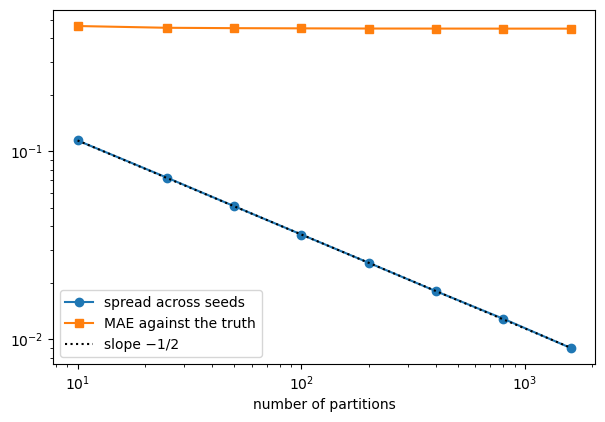

,spread across seeds,MAE against the truth,seconds per run
partitions,,,
10,0.1143,0.4638,0.2114
25,0.0726,0.4540,0.2693
50,0.0512,0.4518,0.4557
100,0.0361,0.4507,0.8182
200,0.0256,0.4498,1.4956
400,0.0180,0.4495,2.9135
800,0.0129,0.4493,7.8952
1600,0.0090,0.4492,12.1298


In [2]:
counts = [10, 25, 50, 100, 200, 400, 800, 1600]
seeds = range(8)
maps, seconds = {}, {}
for T in counts:
    start = time.perf_counter()
    maps[T] = np.stack([esi_griddata(points, values, xi, local_interpolator="sharpidw", n_partitions=T, alpha=alpha,
                                     seed=s).estimation() for s in seeds])
    seconds[T] = (time.perf_counter() - start) / len(seeds)

table = pd.DataFrame({T: {"spread across seeds": maps[T].std(axis=0).mean(),
                          "MAE against the truth": np.mean([np.abs(m - truth).mean() for m in maps[T]]),
                          "seconds per run": seconds[T]} for T in counts}).T.rename_axis("partitions")
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.loglog(counts, table["spread across seeds"], "o-", label="spread across seeds")
ax.loglog(counts, table["MAE against the truth"], "s-", label="MAE against the truth")
ax.loglog(counts, table["spread across seeds"].iloc[0] * np.sqrt(counts[0] / np.array(counts)), "k:", label="slope −1/2")
ax.set_xlabel("number of partitions"); ax.legend()
plt.show()
table.round(4)

The spread across seeds falls from 0.114 with 10 partitions to 0.009 with 1 600, along the slope
−1/2, each fourfold increase halving it. The error against the truth falls from 0.464 to 0.449 and stops
there. From 200 partitions on it moves only in the fourth decimal, while the spread keeps falling. Beyond
that point more partitions make the map reproducible, not more accurate. The time grows in proportion,
from under a second per run with 100 partitions to 12 s with 1 600.

### Readings that need more partitions

The map of means is one reading. A law read from the members also has quantiles and probabilities of exceedance, which settle at their own pace. With the weighted draw of the same decoder, whose
members carry the spread of the data in each cell, we measure the spread across seeds of the median, of
the 5 % and 95 % quantiles and of the probability of exceeding 1.5, a value one location in twenty of
the field exceeds.

In [3]:
rows = {}
for T in (25, 100, 400, 1600):
    readings = {"median": [], "5 % quantile": [], "95 % quantile": [], "probability above 1.5": []}
    for s in seeds:
        members = esi_griddata(points, values, xi, local_interpolator="wdraw_sharpidw", n_partitions=T, alpha=alpha,
                               seed=s).esi_samples()
        low, mid, high = np.percentile(members, [5, 50, 95], axis=-1)
        readings["median"].append(mid); readings["5 % quantile"].append(low); readings["95 % quantile"].append(high)
        readings["probability above 1.5"].append(np.mean(members > 1.5, axis=-1))
    rows[T] = {name: np.stack(r).std(axis=0).mean() for name, r in readings.items()}
print(f"share of the field above 1.5: {np.mean(truth > 1.5):.2f}")
pd.DataFrame(rows).T.rename_axis("partitions").round(4)

share of the field above 1.5: 0.05


,median,5 % quantile,95 % quantile,probability above 1.5
partitions,,,,
25,0.1228,0.2043,0.2091,0.0180
100,0.0603,0.1213,0.1212,0.0095
400,0.0298,0.0646,0.0629,0.0048
1600,0.0145,0.0330,0.0321,0.0024


The 5 % and 95 % quantiles spread about twice as much as the median at every number of partitions,
0.12 against 0.06 with 100, so they need about four times as many partitions for the same stability. The
probability above 1.5 spreads by 0.0095 with 100 partitions, about a fifth of the share of the field it
describes, and by 0.0024 with 1 600.

### Choosing the number

A run is close enough to its limit when the spread across seeds is small next to the error that remains
anyway. Fitting the measured spreads to $c / \sqrt T$ gives $c$. Asking the spread to be a tenth of the
error floor, read at the largest $T$, gives the number of partitions.

In [4]:
c = np.exp(np.mean(np.log(table["spread across seeds"]) + 0.5 * np.log(table.index.values)))
floor = table["MAE against the truth"].iloc[-1]
needed = int(np.ceil((c / (0.1 * floor)) ** 2))
print(f"c = {c:.3f}, error floor {floor:.3f}, partitions for a spread of a tenth of the floor: {needed}")

c = 0.362, error floor 0.449, partitions for a spread of a tenth of the floor: 65


With $c = 0.36$ and a floor of 0.449, a spread of a tenth of the floor needs 65 partitions for the map of
means. The tails need about four times as many, some 250 to 300, and a probability of a rarer event more
still. A few hundred partitions suit most uses on this field. A search, which only ranks settings, can
run with fewer.

## Pitfalls

- **More partitions to fix a poor map.** The error against the truth settles at a floor set by the data,
  the granularity and the decoder. Change those to lower it. More partitions only remove the noise of
  the seed.
- **The number of the search kept for the final run.** A search scores many settings, so it runs few
  partitions each. The final run, read for its tails, needs more.
- **The tails read with the map's number.** A 5 % or 95 % quantile, or a probability of a rare event,
  settles more slowly than the mean. Check its spread across two or three seeds.
- **Settings compared at different numbers.** A difference smaller than the spread across seeds says
  nothing. Compare at one number, with several seeds when the difference is small.

## Try it yourself

1. Repeat the two limits with `"adaptiveidw"` and compare the error floors.
2. Measure the spread of the probability above 2.0, rarer than 1.5.
3. Coarsen the granularity (`alpha=0.8`) and watch both the spread and the floor.

## Next

- *Choosing an ensemble with the Pareto search*, for the granularity and the decoder, which set the floor.
- *Uncertainty at a location*, for the law each location gets.
- *The probabilistic decoders*, for the members that carry the spread of the data.
- The documentation's [Ensemble spatial interpolation](https://spatialize.readthedocs.io/en/latest/theory/esi.html)
  (theory).